In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

### 1. Load the dataset

In [2]:
# The bank-full.csv usually uses a semicolon separator
df_bank = pd.read_csv('/content/bank-full.csv', sep=';')

print("Original dataset head:")
print(df_bank.head())
print("\nOriginal dataset info:")
df_bank.info()

Original dataset head:
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may       198         1     -1         0  unknown  no  

Original dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries,

### 2. Preprocessing

In [3]:
# Convert 'yes'/'no' target variable to 1/0
df_bank['y'] = df_bank['y'].apply(lambda x: 1 if x == 'yes' else 0)

# Identify categorical and numerical features
categorical_features = df_bank.select_dtypes(include=['object']).columns.tolist()
# Remove the target variable 'y' from categorical features if it was included
if 'y' in categorical_features:
    categorical_features.remove('y')

numerical_features = df_bank.select_dtypes(include=['int64', 'float64']).columns.tolist()
# Remove the target variable 'y' from numerical features
if 'y' in numerical_features:
    numerical_features.remove('y')

In [4]:
# One-hot encode categorical features
df_encoded = pd.get_dummies(df_bank, columns=categorical_features, drop_first=True)

In [5]:
# Define features (X) and target (y)
X = df_encoded.drop('y', axis=1)
y = df_encoded['y']

print("\nProcessed dataset head (after one-hot encoding):")
print(X.head())
print("\nTarget variable distribution:")
print(y.value_counts())


Processed dataset head (after one-hot encoding):
   age  balance  day  duration  campaign  pdays  previous  job_blue-collar  \
0   58     2143    5       261         1     -1         0            False   
1   44       29    5       151         1     -1         0            False   
2   33        2    5        76         1     -1         0            False   
3   47     1506    5        92         1     -1         0             True   
4   33        1    5       198         1     -1         0            False   

   job_entrepreneur  job_housemaid  ...  month_jul  month_jun  month_mar  \
0             False          False  ...      False      False      False   
1             False          False  ...      False      False      False   
2              True          False  ...      False      False      False   
3             False          False  ...      False      False      False   
4             False          False  ...      False      False      False   

   month_may  month_nov 

### 3. Split the dataset into training and testing sets

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print(f"\nTraining set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")


Training set size: 33908 samples
Testing set size: 11303 samples


### 4. Build and compare Decision Tree classifiers (Entropy vs. Gini)

In [7]:
# Decision Tree with Entropy criterion
model_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42, max_depth=5)
model_entropy.fit(X_train, y_train)

# Prediction and Accuracy for Entropy model
y_pred_entropy = model_entropy.predict(X_test)
accuracy_entropy = accuracy_score(y_test, y_pred_entropy)
print(f"\nAccuracy (Entropy criterion): {accuracy_entropy:.4f}")


Accuracy (Entropy criterion): 0.8957


In [8]:
# Decision Tree with Gini criterion
model_gini = DecisionTreeClassifier(criterion='gini', random_state=42, max_depth=5)
model_gini.fit(X_train, y_train)

# Prediction and Accuracy for Gini model
y_pred_gini = model_gini.predict(X_test)
accuracy_gini = accuracy_score(y_test, y_pred_gini)
print(f"Accuracy (Gini criterion): {accuracy_gini:.4f}")

Accuracy (Gini criterion): 0.8992


### 5. Visualize the Decision Trees

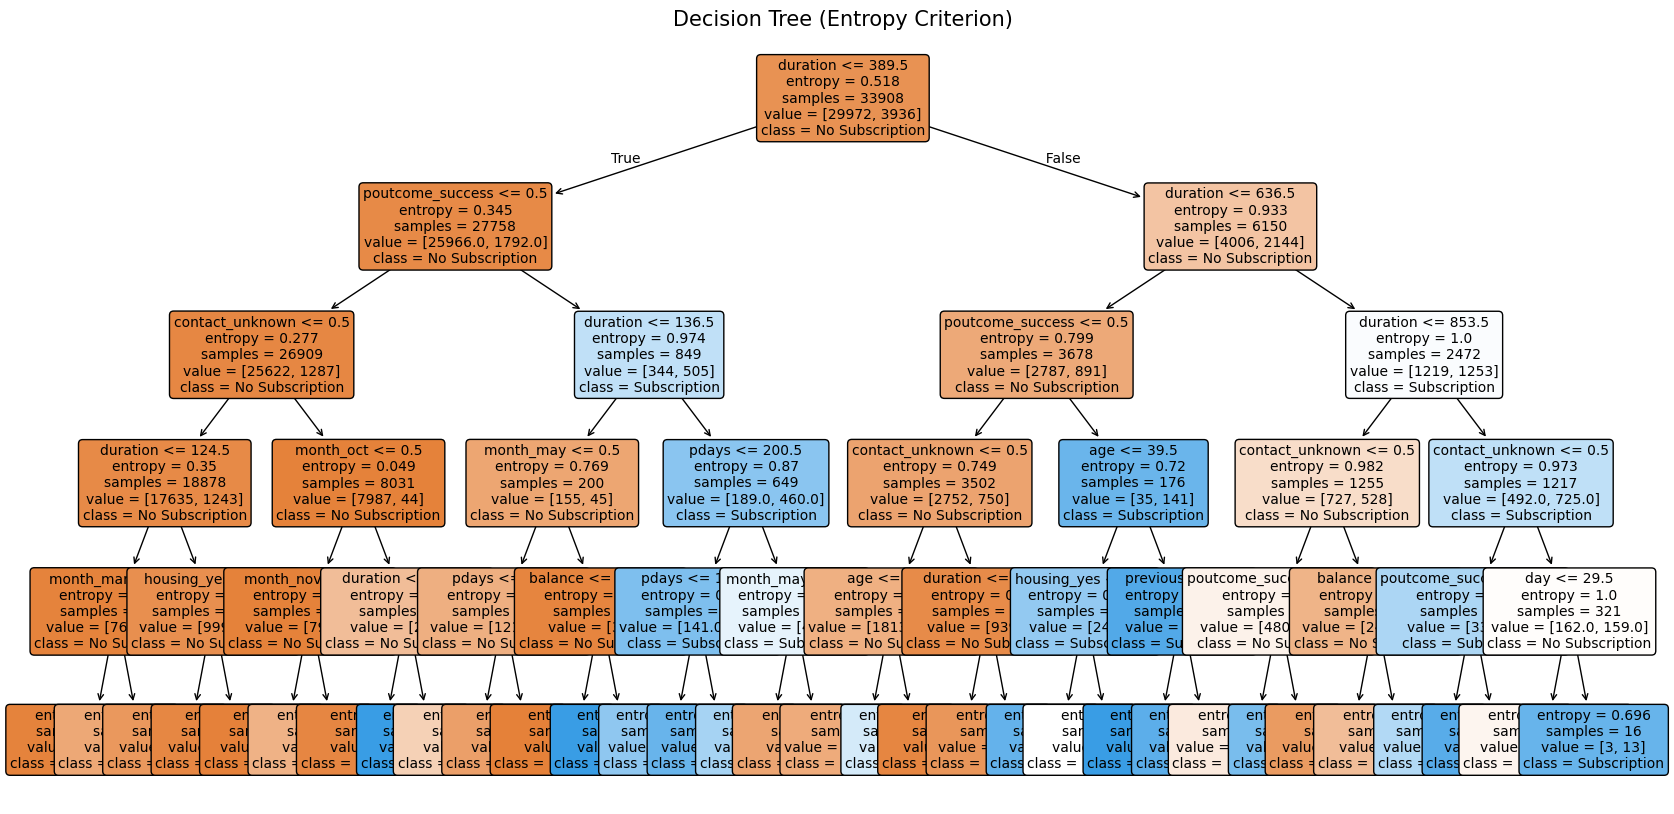

In [9]:
# Plot Entropy Tree
plt.figure(figsize=(20, 10))
plot_tree(model_entropy,
          feature_names=X.columns.tolist(),
          class_names=['No Subscription', 'Subscription'],
          filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree (Entropy Criterion)', fontsize=15)
plt.show()

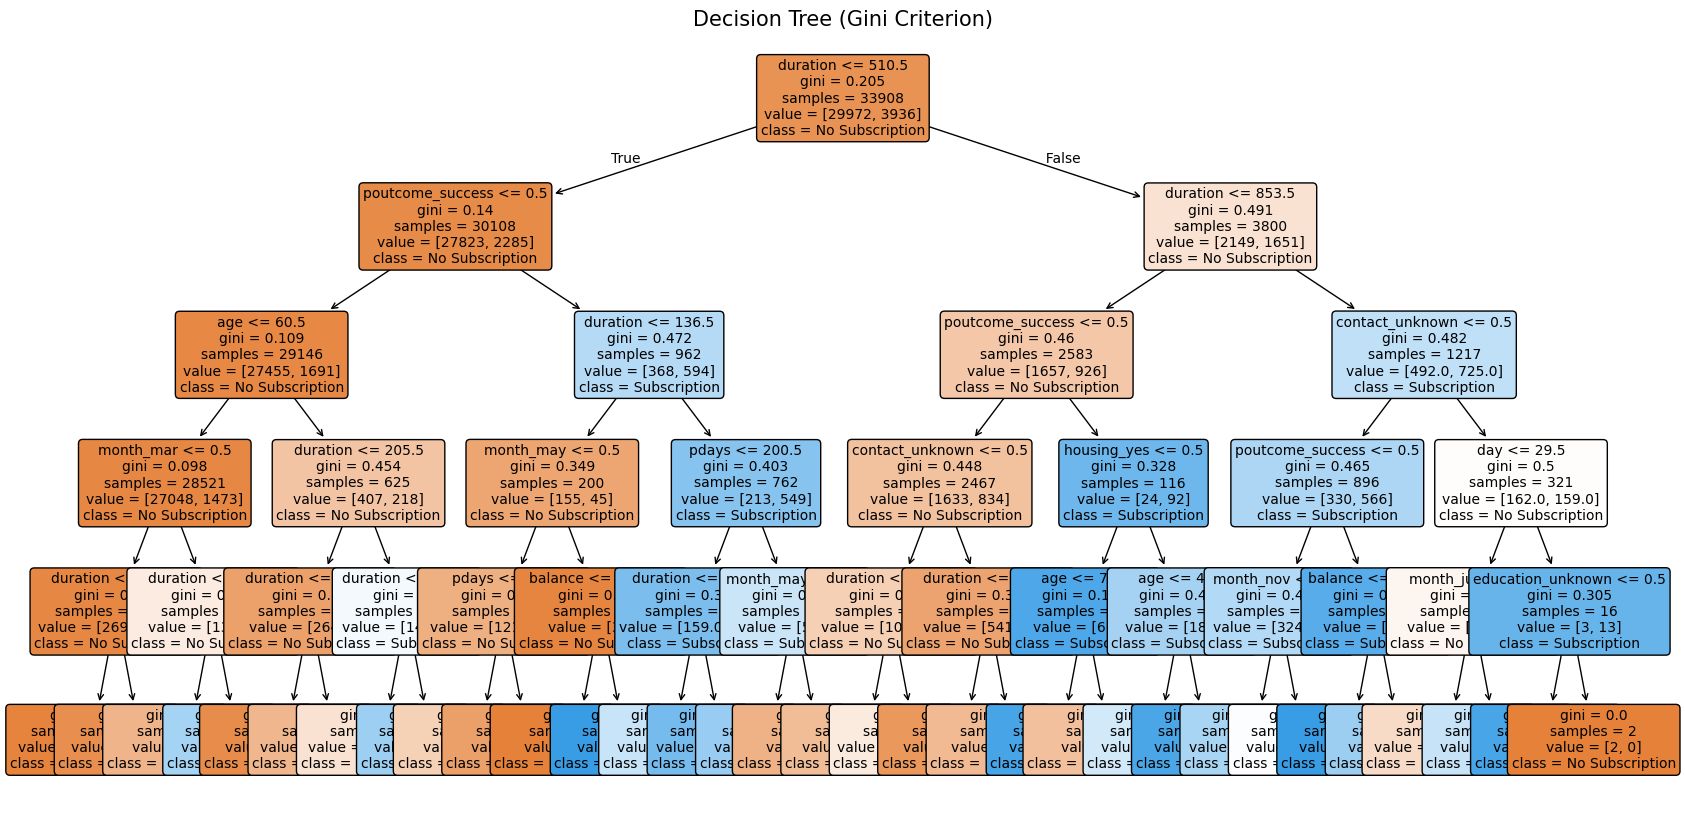

In [10]:
# Plot Gini Tree
plt.figure(figsize=(20, 10))
plot_tree(model_gini,
          feature_names=X.columns.tolist(),
          class_names=['No Subscription', 'Subscription'],
          filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree (Gini Criterion)', fontsize=15)
plt.show()

### 6. Identify the most important features

In [11]:
feature_importances_entropy = pd.Series(model_entropy.feature_importances_, index=X.columns).sort_values(ascending=False)
feature_importances_gini = pd.Series(model_gini.feature_importances_, index=X.columns).sort_values(ascending=False)

print("\nMost important features (Entropy model):\n", feature_importances_entropy.head(10))
print("\nMost important features (Gini model):\n", feature_importances_gini.head(10))


Most important features (Entropy model):
 duration            0.546236
poutcome_success    0.253613
contact_unknown     0.105294
housing_yes         0.047394
month_mar           0.010676
month_oct           0.009077
age                 0.008867
month_nov           0.007709
pdays               0.003976
month_may           0.003346
dtype: float64

Most important features (Gini model):
 duration            0.569760
poutcome_success    0.300516
age                 0.053279
month_mar           0.038534
contact_unknown     0.017941
month_may           0.005048
pdays               0.004433
balance             0.002042
month_jun           0.001891
housing_yes         0.001841
dtype: float64


In [12]:
print("\nAssignment completed: Loaded data, preprocessed, built and compared models, visualized trees, and identified feature importance.")


Assignment completed: Loaded data, preprocessed, built and compared models, visualized trees, and identified feature importance.
